In [22]:
# %%
# %%
"""Notebook-friendly low-rank version of the Hebbian attractor experiment.

Run this file cell by cell in an editor that understands ``# %%`` cells.  The
simulation stores only pattern projections over time.  Plotting is deliberately
left at top level so axes, limits, colors, and annotations are easy to adjust.

The weight matrix convention is:

    W = sum(np.outer(u, v) for u, v in W_components)

The dense n-by-n matrix W is never constructed.
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


def gaussian_laplace_mixture(
    n,
    laplace_weight=0.5,
    laplace_loc=0.0,
    laplace_scale=1.0,
    gaussian_mean=0.0,
    gaussian_std=1.0,
    seed=None,
):
    rng = np.random.default_rng(seed)

    # True selects the Laplace component
    use_laplace = rng.random(n) < laplace_weight

    samples = np.empty(n)
    samples[use_laplace] = rng.laplace(
        laplace_loc, laplace_scale, use_laplace.sum()
    )
    samples[~use_laplace] = rng.normal(
        gaussian_mean, gaussian_std, (~use_laplace).sum()
    )

    return samples


def gaussian_uniform_mixture(
    n,
    uniform_weight=0.5,
    uniform_low=-2.0,
    uniform_high=2.0,
    gaussian_mean=0.0,
    gaussian_std=1.0,
    seed=None,
):
    rng = np.random.default_rng(seed)

    # True selects the Uniform component
    use_uniform = rng.random(n) < uniform_weight

    samples = np.empty(n)
    samples[use_uniform] = rng.uniform(
        uniform_low, uniform_high, use_uniform.sum()
    )
    samples[~use_uniform] = rng.normal(
        gaussian_mean, gaussian_std, (~use_uniform).sum()
    )

    return samples


# %%
# Low-rank helpers
def generate_patterns(distribution, num_patterns, pattern_size, rng=None,
                      dtype=np.float64, a_mixture=0.1):
    """Return patterns with shape (num_patterns, pattern_size)."""
    rng = np.random.default_rng() if rng is None else rng
    shape = (num_patterns, pattern_size)

    if distribution == "gaussian":
        xi = rng.standard_normal(shape)
    elif distribution == "laplace":
        xi = rng.laplace(loc=0.0, scale=1.0, size=shape)
    elif distribution == "uniform":
        xi = rng.uniform(low=-2.0, high=2.0, size=shape)
    elif distribution == "gaussian_laplace_mixture":
        xi = gaussian_laplace_mixture(
            num_patterns * pattern_size,
            laplace_weight=a_mixture,
            laplace_loc=0.0,
            laplace_scale=1.0,
            gaussian_mean=0.0,
            gaussian_std=1.0,
            seed=rng.integers(0, 2**32 - 1),
        ).reshape(shape)
    elif distribution == "gaussian_uniform_mixture":
        xi = gaussian_uniform_mixture(
            num_patterns * pattern_size,
            uniform_weight=a_mixture,
            uniform_low=-2.0,
            uniform_high=2.0,
            gaussian_mean=0.0,
            gaussian_std=1.0,
            seed=rng.integers(0, 2**32 - 1),
        ).reshape(shape)
    else:
        raise ValueError(f"Unsupported distribution type: {distribution}")

    return xi.astype(dtype, copy=False)


def hebbian_components(xi, pattern_weights=None, output_transform=None,
                       normalize=True):
    """Return rank-one pairs representing the Hebbian weight matrix.

    The returned list represents

        W = (output_transform @ xi).T @ pattern_weights @ xi / n

    using only p rank-one terms, including when pattern_weights is not diagonal.
    """
    xi = np.asarray(xi)
    if xi.ndim != 2:
        raise ValueError("xi must have shape (num_patterns, pattern_size)")

    num_patterns, pattern_size = xi.shape

    if pattern_weights is None:
        pattern_weights = np.eye(num_patterns, dtype=xi.dtype)
    else:
        pattern_weights = np.asarray(pattern_weights, dtype=xi.dtype)
        expected = (num_patterns, num_patterns)
        if pattern_weights.shape != expected:
            raise ValueError(
                f"pattern_weights must have shape {expected}, "
                f"got {pattern_weights.shape}"
            )

    if output_transform is None:
        output_patterns = xi
    else:
        output_transform = np.asarray(output_transform, dtype=xi.dtype)
        expected = (num_patterns, num_patterns)
        if output_transform.shape != expected:
            raise ValueError(
                f"output_transform must have shape {expected}, "
                f"got {output_transform.shape}"
            )
        output_patterns = output_transform @ xi

    scale = 1.0 / pattern_size if normalize else 1.0
    weighted_input_patterns = scale * (pattern_weights @ xi)

    return [
        (output_patterns[a], weighted_input_patterns[a])
        for a in range(num_patterns)
    ]


def apply_rank_one_components(x, components):
    """Compute x @ W where W is a list of rank-one (u, v) pairs."""
    x = np.asarray(x)
    if x.ndim != 2:
        raise ValueError("x must have shape (batch_size, state_size)")

    result = np.zeros_like(x)
    for u, v in components:
        u = np.asarray(u)
        v = np.asarray(v)
        expected = (x.shape[1],)
        if u.shape != expected or v.shape != expected:
            raise ValueError(
                f"Each u and v must have shape {expected}; "
                f"got {u.shape} and {v.shape}"
            )
        # x @ outer(u, v) == outer(x @ u, v)
        result += (x @ u)[:, None] * v[None, :]

    return result


def run_dynamics(x0, W_components, projection_patterns, phi, g=2.0,
                 num_steps=100):
    """Run dynamics, retaining only projections rather than full trajectories."""
    x = np.asarray(x0).copy()
    projection_patterns = np.asarray(projection_patterns)

    projections = np.empty(
        (num_steps + 1, x.shape[0], projection_patterns.shape[0]),
        dtype=x.dtype,
    )
    projections[0] = x @ projection_patterns.T

    for t in range(1, num_steps + 1):
        h = g * apply_rank_one_components(x, W_components)
        x = phi(h)
        projections[t] = x @ projection_patterns.T

    return x, projections


# %%
# Nonlinearities
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -60.0, 60.0)))


def relu(x):
    return np.maximum(0.0, x)


phi = sigmoid


# %%
# Experiment configuration -- edit this cell most often.
DISTRIBUTIONS = (
    "gaussian",
    "laplace",
    "uniform",
    "gaussian_laplace_mixture",
    "gaussian_uniform_mixture",
)
RESULTS_DIR = Path("distribution_results_2M")  # change this to save elsewhere
sample_from = "equally_spaced_from_circle"

n = 2_000_000                     # state dimension
p = 2                          # number of Hebbian patterns
n_k = 40                       # number of initial states
num_steps = 100
g = 4.6

seed = None                    # use an integer for reproducibility
dtype = np.float64             # np.float32 uses about half the memory

# One simulation is run for each entry. Examples:
#   [None]       -> baseline only
#   [None, 0, 1] -> baseline plus separate changes to patterns 0 and 1
dim_to_perturb = [None]
pattern_strength_delta = 0.0   # +0.10 strengthens; -0.10 weakens

# Optional q perturbation: outer_perturb_amp * q q.T
outer_perturb_amp = 0.0
outer_perturb_pattern = 0
outer_perturb_offset = 0.4

# Arbitrary extra terms can be appended as (u, v) pairs. Each pair adds u v.T.
# Example, after xi exists:
# additional_rank_one_components = [(0.05 * xi[0], xi[1])]
additional_rank_one_components = []


# %%
# Run every distribution and save only the data needed by the plots.
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for distribution in DISTRIBUTIONS:
    print(f"Running distribution: {distribution}")
    rng = np.random.default_rng(seed)
    xi = generate_patterns(distribution, p, n, rng=rng, dtype=dtype)

    if sample_from == "positive_orthant":
        bound_off_zero = 0.1
        k = rng.random((n_k, p)) * (1.0 - bound_off_zero) + bound_off_zero
    elif sample_from == "random_everywhere":
        k = rng.random((n_k, p)) - 0.5
    elif sample_from == "equally_spaced_from_circle":
        if p != 2:
            raise ValueError("equally_spaced_from_circle requires p == 2")
        angles = np.linspace(0.0, 2.0 * np.pi, n_k, endpoint=False)
        k = np.column_stack((np.cos(angles), np.sin(angles)))
    else:
        raise ValueError(
            f"Unsupported initial-state sampling mode: {sample_from}"
        )

    k = k.astype(dtype, copy=False)
    k = k / np.linalg.norm(k, axis=1, keepdims=True)
    x0 = k @ xi
    xi_perturb = (
        xi[outer_perturb_pattern] - outer_perturb_offset
    ) / np.sqrt(n)

    all_projs = []
    for this_dim_to_perturb in dim_to_perturb:
        pattern_weights = np.eye(p, dtype=dtype)
        if this_dim_to_perturb is not None:
            pattern_weights[
                this_dim_to_perturb, this_dim_to_perturb
            ] += pattern_strength_delta

        W_components = hebbian_components(
            xi,
            pattern_weights=pattern_weights,
            output_transform=None,
            normalize=True,
        )

        if outer_perturb_amp != 0.0:
            # alpha*q*q.T == outer(alpha*q, q)
            W_components.append(
                (outer_perturb_amp * xi_perturb, xi_perturb)
            )

        W_components.extend(additional_rank_one_components)
        _, projections = run_dynamics(
            x0,
            W_components,
            projection_patterns=xi,
            phi=phi,
            g=g,
            num_steps=num_steps,
        )
        all_projs.append(projections / n)

    hist_density, hist_edges = np.histogram(
        xi, bins=50, density=True
    )
    np.savez_compressed(
        RESULTS_DIR / f"{distribution}_results.npz",
        distribution=distribution,
        all_projs=np.stack(all_projs),
        hist_density=hist_density,
        hist_edges=hist_edges,
        num_steps=num_steps,
        n_k=n_k,
        p=p,
        g=g,
    )






Running distribution: gaussian


Running distribution: laplace
Running distribution: uniform
Running distribution: gaussian_laplace_mixture
Running distribution: gaussian_uniform_mixture


In [23]:
DISTRIBUTIONS = ('uniform', 'gaussian_uniform_mixture','gaussian','gaussian_laplace_mixture','laplace',)

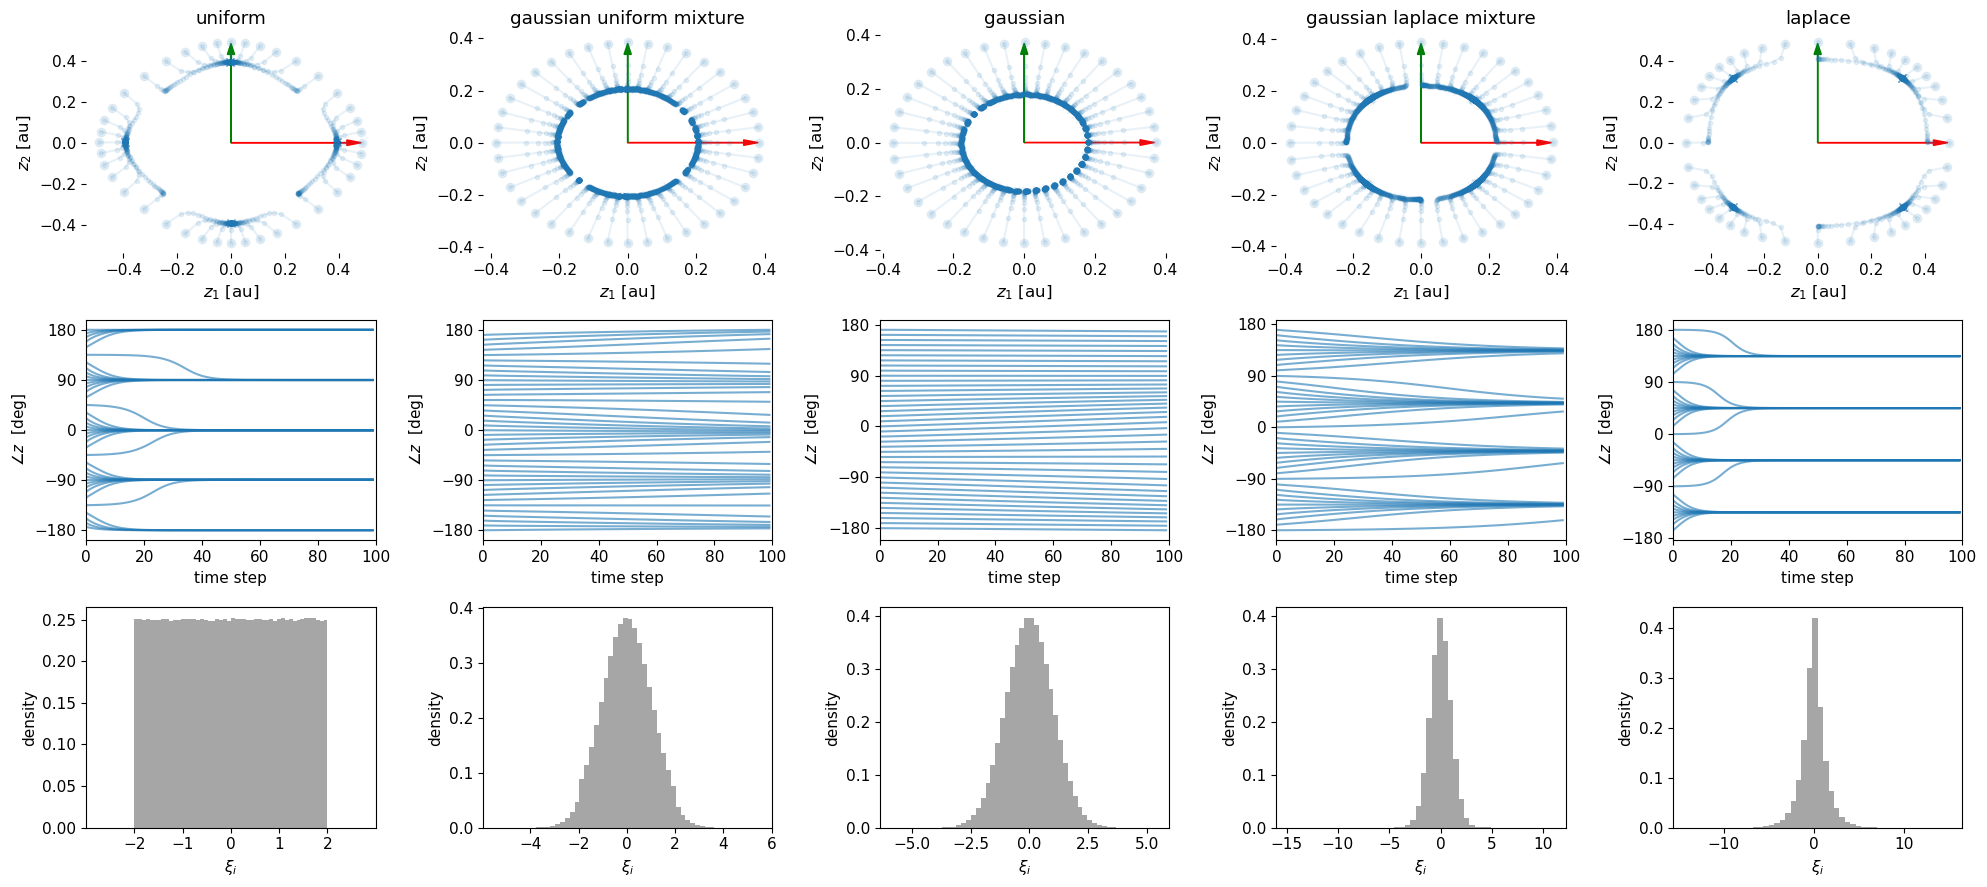

In [24]:
# %%
# Plotting is intentionally flat and reads only the saved files.
fig, axes = plt.subplots(
    3, len(DISTRIBUTIONS),
    figsize=(4 * len(DISTRIBUTIONS), 9),
    squeeze=False,
)

for distribution_column, distribution in enumerate(DISTRIBUTIONS):
    result_path = RESULTS_DIR / f"{distribution}_results.npz"
    with np.load(result_path, allow_pickle=False) as saved:
        all_projs = saved["all_projs"]
        hist_density = saved["hist_density"]
        hist_edges = saved["hist_edges"]
        saved_num_steps = int(saved["num_steps"])
        saved_n_k = int(saved["n_k"])
        saved_p = int(saved["p"])

    if saved_p < 2:
        raise ValueError("The trajectory plot requires at least two patterns")

    trajectory_ax = axes[0, distribution_column]
    angle_ax = axes[1, distribution_column]
    histogram_ax = axes[2, distribution_column]
    colors = plt.cm.tab10(np.linspace(0.0, 1.0, len(all_projs)))
    lim = 1.1 * max(
        np.max(np.abs(projs[1:])) for projs in all_projs
    )
    if lim == 0:
        lim = 1.0

    for condition_index, projs_with_initial in enumerate(all_projs):
        projs = projs_with_initial[1:]
        color = colors[condition_index]

        for i in range(saved_n_k):
            trajectory_ax.plot(
                projs[:, i, 0], projs[:, i, 1],
                ".-", alpha=0.1, color=color,
            )
            trajectory_ax.plot(
                projs[-1, i, 0], projs[-1, i, 1],
                "x", alpha=0.1, color=color,
            )
            trajectory_ax.plot(
                projs[0, i, 0], projs[0, i, 1],
                "o", alpha=0.1, color=color,
            )

            # Argument order matches the original notebook.
            mixture_angle = np.arctan2(
                projs[:, i, 0], projs[:, i, 1]
            )
            mixture_angle = np.unwrap(mixture_angle)
            angle_ax.plot(
                mixture_angle / np.pi * 180,
                "-", alpha=0.6, color=color,
            )

    trajectory_ax.set_title(distribution.replace("_", " "))
    trajectory_ax.set_xlabel("$z_1$ [au]", fontsize=12)
    trajectory_ax.set_ylabel("$z_2$ [au]", fontsize=12)
    trajectory_ax.arrow(
        0, 0, lim * 0.8, 0,
        head_width=lim * 0.05,
        head_length=lim * 0.1,
        fc="r", ec="r",
    )
    trajectory_ax.arrow(
        0, 0, 0, lim * 0.8,
        head_width=lim * 0.05,
        head_length=lim * 0.1,
        fc="g", ec="g",
    )
    trajectory_ax.set_frame_on(False)

    angle_ax.set_xlim([0, min(100, saved_num_steps)])
    angle_ax.set_xlabel("time step")
    angle_ax.set_ylabel("$ \\angle z$  [deg]")
    angle_ax.set_yticks(np.arange(-180, 181, 90))

    histogram_ax.stairs(
        hist_density, hist_edges,
        fill=True, color="gray", alpha=0.7,
    )
    histogram_ax.set_xlabel("$\\xi_i$")
    histogram_ax.set_ylabel("density")
    histogram_ax.set_xlim([np.min(hist_edges)-1, np.max(hist_edges)+1])

plt.tight_layout()
plt.show()


In [25]:
!pwd

/homes/ar2342/one_more_dir/contextual_frogs


NameError: name 'FIGURE_PATH' is not defined

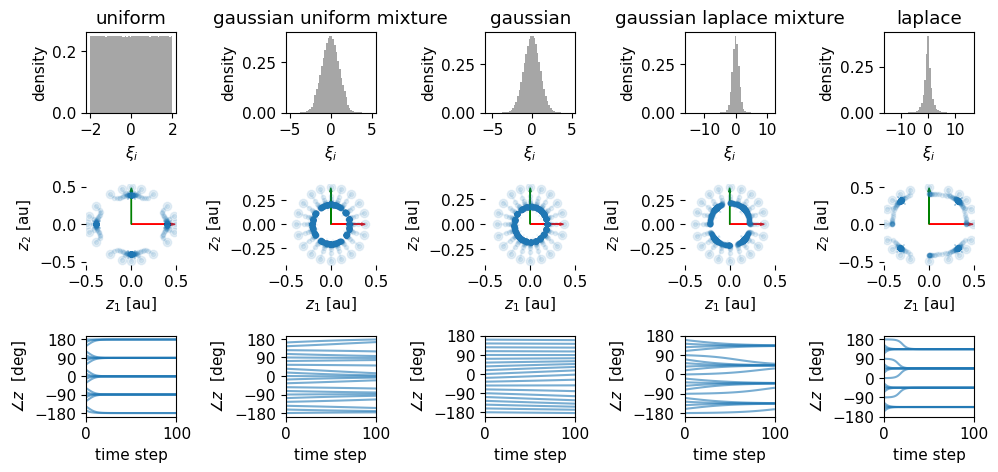

In [26]:
# Plotting is intentionally flat and reads only the saved files.
# Landscape A4 (29.7 x 21 cm), reduced by a 2 cm margin on every side.
a4_usable_width_cm = 29.7 - 2 * 2.0
a4_usable_height_cm = 21.0 - 2 * 2.0
figure_size_inches = (
    a4_usable_width_cm / 2.54,
    a4_usable_width_cm / 2.54 /5 *3 *0.8,
)
plt.rcParams.update({"font.size": 11})

fig, axes = plt.subplots(
    3, len(DISTRIBUTIONS),
    figsize=figure_size_inches,
    squeeze=False,
)

for distribution_column, distribution in enumerate(DISTRIBUTIONS):
    result_path = RESULTS_DIR / f"{distribution}_results.npz"
    with np.load(result_path, allow_pickle=False) as saved:
        all_projs = saved["all_projs"]
        hist_density = saved["hist_density"]
        hist_edges = saved["hist_edges"]
        saved_num_steps = int(saved["num_steps"])
        saved_n_k = int(saved["n_k"])
        saved_p = int(saved["p"])

    if saved_p < 2:
        raise ValueError("The trajectory plot requires at least two patterns")

    trajectory_ax = axes[1, distribution_column]
    angle_ax = axes[2, distribution_column]
    histogram_ax = axes[0, distribution_column]
    colors = plt.cm.tab10(np.linspace(0.0, 1.0, len(all_projs)))
    lim = 1.1 * max(
        np.max(np.abs(projs[1:])) for projs in all_projs
    )
    if lim == 0:
        lim = 1.0

    for condition_index, projs_with_initial in enumerate(all_projs):
        projs = projs_with_initial[1:]
        color = colors[condition_index]

        for i in range(saved_n_k):
            if i % 2 != 0:
                continue
            trajectory_ax.plot(
                projs[:, i, 0], projs[:, i, 1],
                ".-", alpha=0.1, color=color,
            )
            trajectory_ax.plot(
                projs[-1, i, 0], projs[-1, i, 1],
                "x", alpha=0.1, color=color,
            )
            trajectory_ax.plot(
                projs[0, i, 0], projs[0, i, 1],
                "o", alpha=0.1, color=color,
            )

            # Argument order matches the original notebook.
            mixture_angle = np.arctan2(
                projs[:, i, 0], projs[:, i, 1]
            )
            mixture_angle = np.unwrap(mixture_angle)
            angle_ax.plot(
                mixture_angle / np.pi * 180,
                "-", alpha=0.6, color=color,
            )

    # The title identifies the distribution at the top of each column.
    histogram_ax.set_title(distribution.replace("_", " "))
    trajectory_ax.set_xlabel("$z_1$ [au]")
    trajectory_ax.set_ylabel("$z_2$ [au]")
    trajectory_ax.arrow(
        0, 0, lim * 0.8, 0,
        head_width=lim * 0.05,
        head_length=lim * 0.1,
        fc="r", ec="r",
    )
    trajectory_ax.arrow(
        0, 0, 0, lim * 0.8,
        head_width=lim * 0.05,
        head_length=lim * 0.1,
        fc="g", ec="g",
    )
    trajectory_ax.set_frame_on(False)
    trajectory_ax.set_xlim([-0.5, 0.5])

    angle_ax.set_xlim([0, min(100, saved_num_steps)])
    angle_ax.set_xlabel("time step")
    angle_ax.set_ylabel("$ \\angle z$  [deg]")
    angle_ax.set_yticks(np.arange(-180, 181, 90))

    histogram_ax.stairs(
        hist_density, hist_edges,
        fill=True, color="gray", alpha=0.7,
    )
    histogram_ax.set_xlabel("$\\xi_i$")
    histogram_ax.set_ylabel("density")

plt.tight_layout()
fig.savefig(FIGURE_PATH, dpi=600, facecolor="white")
plt.show()